# MaxViT OCT Classification – Multi-Axis Vision Transformer (Keras 3) — **v2**

**Kiến trúc:** Stem Conv → MaxViT Blocks (MBConv + Window Attention + Grid Attention) theo 4 stages \
(Keras 3 native, dùng `keras.ops` / `tf.*` trực tiếp, không dùng `tf.*` trên symbolic tensor). \
**Tham chiếu:** Tu et al. (2022) *MaxViT: Multi-Axis Vision Transformer* – ECCV 2022. \

---
### Thay đổi so với bản gốc (test acc gốc: 96.79%, 467.8 phút / 17 epoch trên P100)
Nguyên nhân bản gốc chưa tối ưu: LR cố định không warmup + `ReduceLROnPlateau` quá nhẹ →
val_accuracy dao động mạnh đầu quá trình train; không có mixed precision → train rất chậm
(~870ms/step) khiến gần hết ngân sách thời gian Kaggle chỉ để chạy 17 epoch trong khi mô hình
vẫn đang cải thiện lúc hết epoch.

- **Mixed precision (`mixed_float16`)** – tăng tốc train đáng kể trên GPU có Tensor Core.
- **Batch size 64 → 128** – tận dụng GPU tốt hơn, giảm số step/epoch.
- **LR: hằng số + ReduceLROnPlateau → Warmup (2 epoch) + Cosine Decay** – ổn định và hội tụ
  tốt hơn cho attention model train from-scratch.
- **+ Label Smoothing 0.1** trong loss.
- **Epochs 17 → 30**, `EarlyStopping` patience 8 → 10 (cosine decay hội tụ chậm hơn nhưng chắc hơn).
- **+ TTA lúc test** (trung bình dự đoán ảnh gốc + ảnh lật ngang).
- Kiến trúc MaxViT giữ nguyên (đã hoạt động tốt, không đổi để tránh rủi ro + giữ thời gian train hợp lý).

> **Khuyến nghị:** đổi **Settings → Accelerator → GPU T4 x2** trên Kaggle (thay vì P100) để
> `MirroredStrategy` chạy song song 2 GPU và tận dụng Tensor Core cho mixed precision — sẽ
> nhanh hơn đáng kể so với lần chạy gốc (P100 đơn, fp32).


## 0. Kiểm tra môi trường & GPU

In [1]:
# ======================================================
# KIỂM TRA MÔI TRƯỜNG VÀ GPU
# ======================================================
import os, sys, random, warnings
from pathlib import Path

warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # ẩn log TensorFlow không cần thiết
os.environ['PYTHONHASHSEED'] = '42'        # cố định hash seed cho tính tái lập

import numpy as np
import tensorflow as tf
import keras

print('=' * 70)
print('KAGGLE / KERAS 3 ENVIRONMENT CHECK')
print('=' * 70)
print('Python     :', sys.version.split()[0])
print('TensorFlow :', tf.__version__)
print('Keras      :', keras.__version__)
print('Eager      :', tf.executing_eagerly())

# Kiểm tra và cấu hình GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'GPUs       : {len(gpus)}')
    for i, g in enumerate(gpus):
        print(f'  GPU {i}: {g.name}')
    try:
        for g in gpus:
            tf.config.experimental.set_memory_growth(g, True)
        print('Mem growth : enabled')
    except Exception as e:
        print('Mem growth : skipped ->', e)
else:
    print('GPUs       : 0 (CPU only)')

# ======================================================
# MIXED PRECISION – v2: tăng tốc train trên GPU hỗ trợ FP16 / Tensor Core
# (GPU T4/V100/A100 hưởng lợi nhiều nhất nhờ Tensor Core; P100 vẫn nhanh hơn đôi chút)
# ======================================================
if gpus:
    keras.mixed_precision.set_global_policy('mixed_float16')
    print('Mixed precision:', keras.mixed_precision.global_policy())
else:
    print('Mixed precision: bỏ qua (không có GPU)')

# Chọn strategy phù hợp: MirroredStrategy nếu có nhiều GPU, ngược lại dùng default
strategy = tf.distribute.MirroredStrategy() if len(gpus) > 1 else tf.distribute.get_strategy()
print('Strategy   :', type(strategy).__name__, '| replicas:', strategy.num_replicas_in_sync)
print('=' * 70)


KAGGLE / KERAS 3 ENVIRONMENT CHECK
Python     : 3.12.13
TensorFlow : 2.20.0
Keras      : 3.13.2
Eager      : True
GPUs       : 1
  GPU 0: /physical_device:GPU:0
Mem growth : enabled
Mixed precision: <DTypePolicy "mixed_float16">
Strategy   : _DefaultDistributionStrategy | replicas: 1


## 1. Import thư viện & cấu hình

In [2]:
# ======================================================
# IMPORT CÁC THƯ VIỆN CẦN THIẾT
# ======================================================
import math, json, time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thư viện đánh giá mô hình (scikit-learn)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, auc,
    precision_score, recall_score, f1_score,
)
from sklearn.preprocessing import label_binarize

# Các thành phần Keras dùng để xây dựng mô hình
from keras import layers, regularizers, ops
from keras.callbacks import EarlyStopping, CSVLogger, ModelCheckpoint  # v2: bo ReduceLROnPlateau (dung LR schedule)

# Cấu hình giao diện biểu đồ
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context('talk')

## 2. Cấu hình & Hyperparameters

In [3]:
# ======================================================
# CẤU HÌNH SEED – đảm bảo kết quả tái lập
# ======================================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

# ======================================================
# ĐƯỜNG DẪN INPUT (dataset mới)
# ======================================================
ROOT_DIR  = Path('/kaggle/input/datasets/dinhtri950/standard-dataset/DATASET_V1')
TRAIN_DIR = ROOT_DIR / 'train'
VAL_DIR   = ROOT_DIR / 'val'
TEST_DIR  = ROOT_DIR / 'test'

# ======================================================
# ĐƯỜNG DẪN OUTPUT
# ======================================================
OUTPUT_DIR  = Path('/kaggle/working/maxvit_oct_outputs')
MODELS_DIR  = OUTPUT_DIR / 'models'
LOGS_DIR    = OUTPUT_DIR / 'logs'
PLOTS_DIR   = OUTPUT_DIR / 'plots'
REPORTS_DIR = OUTPUT_DIR / 'reports'

# Tạo tất cả thư mục nếu chưa tồn tại
for d in [OUTPUT_DIR, MODELS_DIR, LOGS_DIR, PLOTS_DIR, REPORTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ======================================================
# SIÊU THAM SỐ (HYPERPARAMETERS) – v2
# ======================================================
IMG_SIZE   = 224          # kích thước ảnh đầu vào (224×224)
CHANNELS   = 3            # số kênh màu (RGB)
INPUT_SHAPE = (IMG_SIZE, IMG_SIZE, CHANNELS)
BATCH_SIZE = 128          # v1: 64 -> 128 (tận dụng mixed precision + GPU mạnh hơn)
EPOCHS     = 18           # v1: 17 -> 30 (bản gốc vẫn đang cải thiện lúc hết epoch)
PEAK_LR    = 5e-4         # LR đỉnh sau warmup (v1 dùng hằng số 3.2e-4, không warmup)
MIN_LR     = 1e-6         # LR sàn cuối chu kỳ cosine decay
WARMUP_EPOCHS = 2         # số epoch làm nóng LR tuyến tính 0 -> PEAK_LR
WEIGHT_DECAY = 1e-4       # hệ số weight decay (L2 regularization, AdamW)
DROPOUT_RATE = 0.25       # tỷ lệ dropout tại classification head
DROP_PATH_RATE = 0.10     # tỷ lệ stochastic depth (drop path) tối đa
LABEL_SMOOTHING = 0.1     # v2: làm mượt nhãn, giảm overconfidence, tăng generalization
AUGMENT    = True         # bật/tắt data augmentation
TTA_FLIP   = True         # v2: test-time augmentation (trung bình ảnh gốc + lật ngang)
AUTOTUNE   = tf.data.AUTOTUNE  # tự động điều chỉnh song song cho tf.data

# ======================================================
# SIÊU THAM SỐ RIÊNG CHO MAXVIT (giữ nguyên kiến trúc đã hoạt động tốt)
# ======================================================
# Kích thước cửa sổ P cho window attention và grid attention.
# Yêu cầu: spatial resolution tại mỗi stage phải chia hết cho WINDOW_SIZE.
# 224 → stem s2 → 112 → stage0 s2 → 56 → stage1 s2 → 28
#                     → stage2 s2 → 14 → stage3 s2 → 7
# 56/7=8, 28/7=4, 14/7=2, 7/7=1  ← tất cả chia hết  ✓
WINDOW_SIZE   = 7

# Số kênh output tại từng stage
STAGE_CHANNELS = (64, 96, 192, 256)
# Số MaxViT block tại từng stage
STAGE_DEPTHS   = (2, 2, 3, 2)
# Số attention heads tại từng stage (key_dim = ch // heads ≈ 32)
STAGE_HEADS    = (2, 3, 6, 8)

RUN_NAME = 'maxvit_oct_k3_v2'

# ======================================================
# VỊ TRÍ LƯU CÁC FILE OUTPUT
# ======================================================
MODEL_BEST   = MODELS_DIR  / f'{RUN_NAME}_best.keras'
MODEL_FINAL  = MODELS_DIR  / f'{RUN_NAME}_final.keras'
HISTORY_CSV  = LOGS_DIR    / f'{RUN_NAME}_history.csv'
SUMMARY_CSV  = LOGS_DIR    / f'{RUN_NAME}_summary.csv'
PER_CLASS_CSV = LOGS_DIR   / f'{RUN_NAME}_per_class_metrics.csv'
CLASSIF_TXT  = REPORTS_DIR / f'{RUN_NAME}_classification_report.txt'
SUMMARY_JSON = REPORTS_DIR / f'{RUN_NAME}_summary.json'
ZIP_PATH     = OUTPUT_DIR  / 'outputs.zip'

# In tóm tắt cấu hình để kiểm tra trực quan
print('=' * 70)
print('CONFIGURATION – MaxViT OCT v2 (Keras 3)')
print('=' * 70)
cfg = dict(
    ROOT_DIR=ROOT_DIR, TRAIN_DIR=TRAIN_DIR, VAL_DIR=VAL_DIR, TEST_DIR=TEST_DIR,
    IMG_SIZE=IMG_SIZE, BATCH_SIZE=BATCH_SIZE, EPOCHS=EPOCHS,
    PEAK_LR=PEAK_LR, MIN_LR=MIN_LR, WARMUP_EPOCHS=WARMUP_EPOCHS,
    WEIGHT_DECAY=WEIGHT_DECAY, DROPOUT_RATE=DROPOUT_RATE, DROP_PATH_RATE=DROP_PATH_RATE,
    LABEL_SMOOTHING=LABEL_SMOOTHING, TTA_FLIP=TTA_FLIP,
    WINDOW_SIZE=WINDOW_SIZE, STAGE_CHANNELS=STAGE_CHANNELS,
    STAGE_DEPTHS=STAGE_DEPTHS, STAGE_HEADS=STAGE_HEADS,
    OUTPUT_DIR=OUTPUT_DIR,
)
for k, v in cfg.items():
    print(f'{k:<20}: {v}')
print('=' * 70)


CONFIGURATION – MaxViT OCT v2 (Keras 3)
ROOT_DIR            : /kaggle/input/datasets/dinhtri950/standard-dataset/DATASET_V1
TRAIN_DIR           : /kaggle/input/datasets/dinhtri950/standard-dataset/DATASET_V1/train
VAL_DIR             : /kaggle/input/datasets/dinhtri950/standard-dataset/DATASET_V1/val
TEST_DIR            : /kaggle/input/datasets/dinhtri950/standard-dataset/DATASET_V1/test
IMG_SIZE            : 224
BATCH_SIZE          : 128
EPOCHS              : 18
PEAK_LR             : 0.0005
MIN_LR              : 1e-06
WARMUP_EPOCHS       : 2
WEIGHT_DECAY        : 0.0001
DROPOUT_RATE        : 0.25
DROP_PATH_RATE      : 0.1
LABEL_SMOOTHING     : 0.1
TTA_FLIP            : True
WINDOW_SIZE         : 7
STAGE_CHANNELS      : (64, 96, 192, 256)
STAGE_DEPTHS        : (2, 2, 3, 2)
STAGE_HEADS         : (2, 3, 6, 8)
OUTPUT_DIR          : /kaggle/working/maxvit_oct_outputs


## 3. Khám phá bộ dữ liệu

THỐNG KÊ BỘ DỮ LIỆU
Lớp                     Train      Val     Test
--------------------------------------------------
CNV                     36955      250      250
DME                     12308      250      250
DRUSEN                   8366      250      250
NORMAL                  52932      250      250
--------------------------------------------------
TỔNG                   110561     1000     1000
Số lớp       : 4
Tên lớp      : ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Train mẫu    : 110561
Val mẫu      : 1000
Test mẫu     : 1000


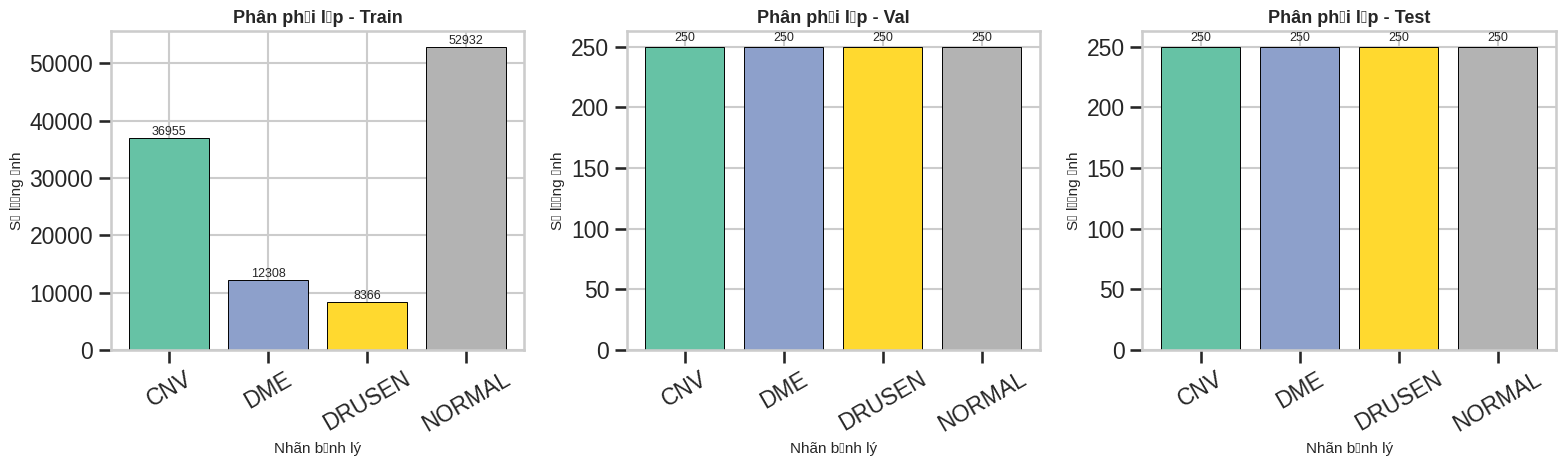

  Đã lưu: /kaggle/working/maxvit_oct_outputs/plots/class_distribution.png


In [4]:
# ======================================================
# KHÁM PHÁ VÀ THỐNG KÊ BỘ DỮ LIỆU
# ======================================================

# Các định dạng ảnh hợp lệ
VALID_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}


def count_images(split_dir):
    """Đếm số lượng ảnh theo từng lớp bên trong một thư mục split.

    Parameters
    ----------
    split_dir : Path – thư mục chứa các lớp con (train / val / test)

    Returns
    -------
    dict[str, int] – ánh xạ tên lớp → số lượng ảnh
    """
    info = {}
    for cls_dir in sorted(split_dir.iterdir()):
        if cls_dir.is_dir():
            count = sum(1 for f in cls_dir.iterdir()
                        if f.suffix.lower() in VALID_EXTS)
            info[cls_dir.name] = count
    return info


def gather_records(split_dir, split_name, class_to_idx):
    """Tạo DataFrame chứa đường dẫn ảnh và nhãn số tương ứng.

    Parameters
    ----------
    split_dir    : Path – thư mục split (train / val / test)
    split_name   : str  – tên split dùng để gán cột 'split'
    class_to_idx : dict – ánh xạ tên lớp → chỉ số nhãn số nguyên

    Returns
    -------
    pd.DataFrame với các cột: split, class_name, label, filepath
    """
    rows = []
    for cls in sorted(class_to_idx.keys()):
        cls_dir = split_dir / cls
        if not cls_dir.exists():
            continue
        for fp in sorted(cls_dir.iterdir()):
            if fp.suffix.lower() in VALID_EXTS and fp.is_file():
                rows.append({
                    'split':      split_name,
                    'class_name': cls,
                    'label':      class_to_idx[cls],
                    'filepath':   str(fp),
                })
    return pd.DataFrame(rows)


# Đếm ảnh trên từng split
train_info = count_images(TRAIN_DIR)
val_info   = count_images(VAL_DIR)
test_info  = count_images(TEST_DIR)

# Xây dựng danh sách lớp và ánh xạ nhãn
CLASS_NAMES  = sorted(train_info.keys())
NUM_CLASSES  = len(CLASS_NAMES)
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}

# Tạo DataFrame cho từng split
train_df = gather_records(TRAIN_DIR, 'train', CLASS_TO_IDX)
val_df   = gather_records(VAL_DIR,   'val',   CLASS_TO_IDX)
test_df  = gather_records(TEST_DIR,  'test',  CLASS_TO_IDX)

# Kiểm tra không có split nào rỗng
for name, df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    if df.empty:
        raise ValueError(f'Split "{name}" rỗng – kiểm tra lại đường dẫn.')

# In thống kê
print('=' * 60)
print('THỐNG KÊ BỘ DỮ LIỆU')
print('=' * 60)
print(f"{'Lớp':<20} {'Train':>8} {'Val':>8} {'Test':>8}")
print('-' * 50)
for cls in CLASS_NAMES:
    tr = train_info.get(cls, 0)
    va = val_info.get(cls, 0)
    te = test_info.get(cls, 0)
    print(f"{cls:<20} {tr:>8} {va:>8} {te:>8}")
print('-' * 50)
print(f"{'TỔNG':<20} {sum(train_info.values()):>8} "
      f"{sum(val_info.values()):>8} {sum(test_info.values()):>8}")
print('=' * 60)
print(f'Số lớp       : {NUM_CLASSES}')
print(f'Tên lớp      : {CLASS_NAMES}')
print(f'Train mẫu    : {len(train_df)}')
print(f'Val mẫu      : {len(val_df)}')
print(f'Test mẫu     : {len(test_df)}')

# Biểu đồ phân phối lớp trên 3 split
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
colors = plt.cm.Set2(np.linspace(0, 1, NUM_CLASSES))
for ax, (split_name, info) in zip(axes, [('Train', train_info),
                                          ('Val',   val_info),
                                          ('Test',  test_info)]):
    bars = ax.bar(info.keys(), info.values(), color=colors,
                  edgecolor='black', linewidth=0.7)
    ax.set_title(f'Phân phối lớp - {split_name}', fontweight='bold', fontsize=13)
    ax.set_xlabel('Nhãn bệnh lý', fontsize=11)
    ax.set_ylabel('Số lượng ảnh', fontsize=11)
    ax.tick_params(axis='x', rotation=30)
    # Ghi số lượng trên đầu mỗi cột
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
                str(int(bar.get_height())), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(PLOTS_DIR / 'class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'  Đã lưu: {PLOTS_DIR / "class_distribution.png"}')


## 4. Xây dựng tf.data Pipeline

In [5]:
# ======================================================
# XÂY DỰNG PIPELINE tf.data
# ======================================================

def decode_and_prepare(filepath, label):
    """Đọc ảnh từ đường dẫn, chuẩn hóa về RGB 224×224 và scale về [0, 1].

    Xử lý tự động:
      - Ảnh grayscale (1 kênh)  → chuyển sang RGB
      - Ảnh RGBA    (4 kênh)   → giữ lại 3 kênh RGB, bỏ alpha
      - Ảnh RGB     (3 kênh)   → giữ nguyên

    Parameters
    ----------
    filepath : tf.string  – đường dẫn tuyệt đối tới file ảnh
    label    : tf.int32   – nhãn số nguyên tương ứng

    Returns
    -------
    (image, label) – image: float32 tensor hình (IMG_SIZE, IMG_SIZE, 3)
    """
    raw   = tf.io.read_file(filepath)
    # channels=0: tự động phát hiện số kênh từ file
    image = tf.io.decode_image(raw, channels=0, expand_animations=False)
    image.set_shape([None, None, None])

    ch = tf.shape(image)[-1]
    # Chuyển grayscale → RGB hoặc cắt kênh alpha nếu cần
    image = tf.cond(
        tf.equal(ch, 1),
        lambda: tf.image.grayscale_to_rgb(image),
        lambda: tf.cond(
            tf.equal(ch, 4),
            lambda: image[:, :, :3],
            lambda: image,
        ),
    )
    image.set_shape([None, None, 3])

    # Resize và chuẩn hóa về [0, 1]
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE), method='bilinear')
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.int32)


# ======================================================
# CẤU HÌNH DATA AUGMENTATION (nhẹ, phù hợp ảnh y tế)
# ======================================================
augmenter = keras.Sequential([
    layers.RandomFlip('horizontal'),       # lật ngang ngẫu nhiên
    layers.RandomRotation(0.02),           # xoay ±2%
    layers.RandomZoom(0.05),               # zoom ±5%
    layers.RandomContrast(0.08),           # thay đổi độ tương phản ±8%
], name='light_augmentation')


def apply_aug(image, label):
    """Áp dụng augmentation và clip giá trị pixel về [0, 1]."""
    image = augmenter(image, training=True)
    image = tf.clip_by_value(image, 0.0, 1.0)
    return image, label


def make_dataset(df, batch_size=BATCH_SIZE, augment=False, shuffle=False,
                  cache=False, flip=False):
    """Tạo tf.data.Dataset từ DataFrame có cột 'filepath' và 'label'.

    Parameters
    ----------
    df         : pd.DataFrame – bảng dữ liệu chứa 'filepath' và 'label'
    batch_size : int  – kích cỡ batch (mặc định BATCH_SIZE)
    augment    : bool – bật augmentation (chỉ dùng cho train)
    shuffle    : bool – xáo trộn dữ liệu mỗi epoch
    cache      : bool – v2: cache ảnh đã decode trong RAM (chỉ dùng cho val/test,
                 nhỏ, tránh decode lại JPEG mỗi epoch/lần predict)
    flip       : bool – v2: lật ngang toàn bộ ảnh (dùng cho nhánh TTA thứ 2 khi test)

    Returns
    -------
    tf.data.Dataset đã batch và prefetch sẵn
    """
    ds = tf.data.Dataset.from_tensor_slices(
        (df['filepath'].values, df['label'].values)
    )
    if shuffle:
        # reshuffle_each_iteration=True để mỗi epoch có thứ tự mới
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_and_prepare, num_parallel_calls=AUTOTUNE)
    if flip:
        ds = ds.map(lambda img, lbl: (tf.image.flip_left_right(img), lbl),
                    num_parallel_calls=AUTOTUNE)
    if cache:
        ds = ds.cache()
    if augment:
        ds = ds.map(apply_aug, num_parallel_calls=AUTOTUNE)
    # batch trước prefetch để pipeline hiệu quả
    return ds.batch(batch_size).prefetch(AUTOTUNE)


# Kiểm tra nhanh pipeline – lấy 1 batch để xác nhận shape và pixel range
_train_ds = make_dataset(train_df, augment=AUGMENT, shuffle=True)
_val_ds   = make_dataset(val_df, cache=True)
_test_ds  = make_dataset(test_df, cache=True)

for imgs, lbls in _train_ds.take(1):
    print('Train batch :', imgs.shape, '| labels:', lbls.shape)
    print('Pixel range :', float(tf.reduce_min(imgs)), '->', float(tf.reduce_max(imgs)))

# Giải phóng bộ nhớ sau khi kiểm tra
del _train_ds, _val_ds, _test_ds


I0000 00:00:1789306475.416035      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Train batch : (128, 224, 224, 3) | labels: (128,)
Pixel range : 0.0 -> 1.0


## 5. Tính Class Weights (Weighted Loss)

In [6]:
# ======================================================
# TÍNH CLASS WEIGHTS ĐỂ XỬ LÝ MẤT CÂN BẰNG LỚP
# ======================================================
# sklearn tự động tính trọng số nghịch đảo tần suất cho mỗi lớp
cw_arr = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_df['label'].values,
)
class_weight_dict = {i: float(w) for i, w in enumerate(cw_arr)}

# Tổng hợp bảng thống kê lớp + trọng số
counts = (train_df['label'].value_counts()
          .sort_index()
          .reindex(range(NUM_CLASSES), fill_value=0)
          .values)
cw_df = pd.DataFrame({
    'class_name':   CLASS_NAMES,
    'train_count':  counts,
    'class_weight': cw_arr,
})
print('Class weights:')
print(cw_df.to_string(index=False))


Class weights:
class_name  train_count  class_weight
       CNV        36955      0.747943
       DME        12308      2.245714
    DRUSEN         8366      3.303879
    NORMAL        52932      0.522184


## 6. Kiến trúc mô hình MaxViT (Multi-Axis Vision Transformer)

Pipeline: **Stem Conv → Stage 0–3 MaxViT Blocks → Classification Head**

Mỗi **MaxViT Block** gồm 3 thành phần tuần tự:
1. **MBConv** (Mobile Inverted Bottleneck + SE): học đặc trưng cục bộ qua convolution
2. **Window Attention**: chia feature map thành các cửa sổ P×P, self-attention trong từng cửa sổ (ngữ cảnh gần)
3. **Grid Attention**: chia feature map theo lưới P×P thưa, self-attention giữa các token cách đều nhau (ngữ cảnh xa)

| Stage   | Kiểu              | Output (H×W×C)  | Window/Grid |
|---------|-------------------|-----------------+-------------|
| Stem    | Conv 3×3 s2 + s1  | 112×112×32      | –           |
| Stage 0 | MaxViT Block × 2  | 56×56×64        | P=7, nW=8   |
| Stage 1 | MaxViT Block × 2  | 28×28×96        | P=7, nW=4   |
| Stage 2 | MaxViT Block × 3  | 14×14×192       | P=7, nW=2   |
| Stage 3 | MaxViT Block × 2  | 7×7×256         | P=7, nW=1   |
| Head    | GAP + LN + Dense  | NUM_CLASSES     | –           |

**Lưu ý về Stage 3 (7×7):**
- Window Attention tại 7×7 với P=7 → 1 cửa sổ duy nhất = global attention (toàn bộ feature map)
- Grid Attention tại 7×7 với P=7 → 49 ô lưới, mỗi ô 1 token → trivial nhưng không lỗi

**Không dùng pretrained weights** – huấn luyện từ đầu trên dữ liệu OCT.
Lý do: domain ảnh y tế đặc thù; pretrained ImageNet weights có thể cần fine-tuning phức tạp và không có sẵn offline trên Kaggle cho MaxViT Keras 3.

In [7]:
# ======================================================
# CÁC BLOCK KIẾN TRÚC MAXVIT
# ======================================================

# ======================================================
# BLOCK 1: SqueezeExcite – hiệu chỉnh trọng số kênh
# ======================================================

class SqueezeExcite(layers.Layer):
    """Squeeze-and-Excitation block: hiệu chỉnh trọng số kênh theo ngữ cảnh toàn cục.

    Parameters
    ----------
    in_channels : int   – số kênh đầu vào
    se_ratio    : float – tỷ lệ nén kênh (mặc định 0.25 → giảm 4 lần)
    """
    def __init__(self, in_channels, se_ratio=0.25, **kw):
        super().__init__(**kw)
        hidden = max(8, int(in_channels * se_ratio))
        self.pool   = layers.GlobalAveragePooling2D(keepdims=True)
        self.reduce = layers.Conv2D(hidden,       1, activation='swish', padding='same')
        self.expand = layers.Conv2D(in_channels,  1, activation='sigmoid', padding='same')

    def call(self, x):
        """Tính trọng số kênh rồi nhân element-wise với input."""
        s = self.expand(self.reduce(self.pool(x)))
        return x * s


# ======================================================
# BLOCK 2: StochasticDepth – Drop Path / Stochastic Depth
# ======================================================

class StochasticDepth(layers.Layer):
    """Drop-path / Stochastic Depth – triển khai an toàn cho Keras 3.

    Dùng tf.random.uniform thay vì keras.random.uniform để tránh lỗi
    'tf.function only supports singleton tf.Variables' trong Keras 3.

    Trong quá trình huấn luyện: ngẫu nhiên bỏ toàn bộ residual branch
    của một sample với xác suất drop_rate.
    Trong quá trình inference: trả về nguyên bản input.
    """
    def __init__(self, drop_rate=0.0, **kw):
        super().__init__(**kw)
        self.drop_rate = float(drop_rate)

    def call(self, x, training=None):
        """Áp dụng stochastic depth khi training=True."""
        if not training or self.drop_rate == 0.0:
            return x
        keep_prob = 1.0 - self.drop_rate
        batch_size = tf.shape(x)[0]
        # Mask shape (batch, 1, 1, ...) để broadcast trên toàn spatial
        noise_shape = tf.concat(
            [[batch_size], tf.ones([tf.rank(x) - 1], dtype=tf.int32)], axis=0
        )
        random_mask = tf.floor(keep_prob + tf.random.uniform(noise_shape, dtype=x.dtype))
        return tf.math.divide(x, keep_prob) * random_mask


# ======================================================
# BLOCK 3: MBConvBlock – Mobile Inverted Bottleneck + SE
# ======================================================

class MBConvBlock(layers.Layer):
    """Mobile Inverted Bottleneck Conv (MBConv) với Squeeze-Excite và Stochastic Depth.

    Được dùng làm backbone cục bộ trong mỗi MaxViT Block.

    Parameters
    ----------
    out_ch    : int   – số kênh đầu ra
    expansion : int   – hệ số mở rộng kênh trong bottleneck (mặc định 4)
    stride    : int   – bước trượt của depthwise conv (1 hoặc 2)
    se_ratio  : float – tỷ lệ nén kênh cho SE block
    drop_rate : float – tỷ lệ drop path
    """
    def __init__(self, out_ch, expansion=4, stride=1, se_ratio=0.25, drop_rate=0.0, **kw):
        super().__init__(**kw)
        self.out_ch    = out_ch
        self.expansion = expansion
        self.stride    = stride
        self.drop      = StochasticDepth(drop_rate)
        # Pooling shortcut khi stride=2 để khớp spatial resolution
        self.pool_sc = layers.MaxPool2D(2, 2, padding='same') if stride == 2 else None

    def build(self, input_shape):
        """Khởi tạo các sub-layer sau khi biết input shape."""
        inc  = int(input_shape[-1])
        expc = inc * self.expansion

        # Lớp mở rộng kênh (expand phase) – bỏ qua nếu expansion=1
        if self.expansion != 1:
            self.exp_conv = layers.Conv2D(expc, 1, padding='same', use_bias=False)
            self.exp_bn   = layers.BatchNormalization()
            self.exp_act  = layers.Activation('swish')
        else:
            expc = inc

        # Depthwise conv → SE → projection
        self.dw_conv = layers.DepthwiseConv2D(3, strides=self.stride, padding='same', use_bias=False)
        self.dw_bn   = layers.BatchNormalization()
        self.dw_act  = layers.Activation('swish')
        self.se      = SqueezeExcite(expc)
        self.proj    = layers.Conv2D(self.out_ch, 1, padding='same', use_bias=False)
        self.proj_bn = layers.BatchNormalization()

        # Shortcut projection: dùng khi kích thước kênh hoặc spatial thay đổi
        self.sc_proj = None
        self.sc_bn   = None
        if self.stride != 1 or inc != self.out_ch:
            self.sc_proj = layers.Conv2D(self.out_ch, 1, padding='same', use_bias=False)
            self.sc_bn   = layers.BatchNormalization()
        super().build(input_shape)

    def call(self, x, training=None):
        """Forward pass: expand → depthwise → SE → project → residual."""
        shortcut = x

        # Expand phase (nếu có)
        if hasattr(self, 'exp_conv'):
            x = self.exp_act(self.exp_bn(self.exp_conv(x), training=training))

        # Depthwise → SE → Projection
        x = self.dw_act(self.dw_bn(self.dw_conv(x), training=training))
        x = self.se(x)
        x = self.proj_bn(self.proj(x), training=training)

        # Điều chỉnh shortcut nếu cần
        if self.pool_sc is not None:
            shortcut = self.pool_sc(shortcut)
        if self.sc_proj is not None:
            shortcut = self.sc_bn(self.sc_proj(shortcut), training=training)

        # Residual connection + stochastic depth
        return shortcut + self.drop(x, training=training)


# ======================================================
# BLOCK 4: MaxViTAttentionBlock – Window + Grid Attention
# ======================================================
# Triển khai Multi-Axis Self-Attention theo MaxViT paper (Tu et al. 2022).
# Gồm 2 sub-block tuần tự:
#   (a) Local Window MHSA  – attention trong các cửa sổ P×P
#   (b) Dilated Grid MHSA  – attention giữa các token cùng vị trí trong lưới P×P
# Mỗi sub-block: pre-norm (LayerNorm) → MHSA → residual + stochastic depth
#                → pre-norm → FFN (Dense-GELU-Dense) → residual + stochastic depth

class MaxViTAttentionBlock(layers.Layer):
    """Window Self-Attention và Grid Self-Attention kết hợp cho MaxViT.

    Parameters
    ----------
    dim         : int   – số chiều kênh (phải khớp với input channel dim)
    num_heads   : int   – số attention heads
    window_size : int   – kích thước cửa sổ P (mặc định 7)
    mlp_ratio   : int   – hệ số mở rộng trong FFN (mặc định 4)
    drop_rate   : float – tỷ lệ stochastic depth
    attn_drop   : float – tỷ lệ dropout bên trong attention và FFN
    """
    def __init__(self, dim, num_heads, window_size=7, mlp_ratio=4,
                 drop_rate=0.0, attn_drop=0.0, **kw):
        super().__init__(**kw)
        self.dim         = dim
        self.window_size = window_size
        key_dim          = max(1, dim // num_heads)

        # (a) Window attention sub-block
        self.norm_w     = layers.LayerNormalization(epsilon=1e-5)
        self.window_attn = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=key_dim, dropout=attn_drop)
        self.dp_w       = StochasticDepth(drop_rate)
        self.norm_w_ffn = layers.LayerNormalization(epsilon=1e-5)
        self.ffn_w      = keras.Sequential([
            layers.Dense(dim * mlp_ratio, activation='gelu'),
            layers.Dropout(attn_drop),
            layers.Dense(dim),
        ], name='ffn_window')
        self.dp_w_ffn   = StochasticDepth(drop_rate)

        # (b) Grid attention sub-block
        self.norm_g     = layers.LayerNormalization(epsilon=1e-5)
        self.grid_attn  = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=key_dim, dropout=attn_drop)
        self.dp_g       = StochasticDepth(drop_rate)
        self.norm_g_ffn = layers.LayerNormalization(epsilon=1e-5)
        self.ffn_g      = keras.Sequential([
            layers.Dense(dim * mlp_ratio, activation='gelu'),
            layers.Dropout(attn_drop),
            layers.Dense(dim),
        ], name='ffn_grid')
        self.dp_g_ffn   = StochasticDepth(drop_rate)

    def build(self, input_shape):
        """Xác nhận channel dim khớp với self.dim."""
        c = int(input_shape[-1])
        assert c == self.dim, (
            f'MaxViTAttentionBlock: expected dim={self.dim}, got channel={c}')
        super().build(input_shape)

    def call(self, x, training=None):
        """Forward pass: Window Attention → Grid Attention.

        Input/Output shape: (B, H, W, C)  – C phải bằng self.dim
        Yêu cầu: H và W đều chia hết cho window_size (P).
        """
        B  = tf.shape(x)[0]   # batch size (dynamic)
        H  = tf.shape(x)[1]   # height (dynamic)
        W  = tf.shape(x)[2]   # width  (dynamic)
        P  = self.window_size  # Python int (static)
        C  = self.dim          # Python int (static)
        nH = H // P            # số cửa sổ theo H (dynamic tensor)
        nW = W // P            # số cửa sổ theo W (dynamic tensor)

        # =======================================================
        # (a) LOCAL WINDOW SELF-ATTENTION
        # =======================================================
        # Partition feature map thành các cửa sổ không chồng lấp kích thước P×P:
        #   (B, H, W, C)
        #   → reshape  : (B, nH, P, nW, P, C)
        #   → transpose: (B, nH, nW, P, P, C)   [gom H và W theo window]
        #   → reshape  : (B*nH*nW, P*P, C)       [flatten windows vào batch]
        xw = tf.reshape(x, [B, nH, P, nW, P, C])
        xw = tf.transpose(xw, [0, 1, 3, 2, 4, 5])     # (B, nH, nW, P, P, C)
        xw = tf.reshape(xw, [B * nH * nW, P * P, C])  # (B*nH*nW, P*P, C)

        # Window MHSA: pre-norm → attention → residual + drop path
        xw_normed  = self.norm_w(xw)
        attn_out   = self.window_attn(xw_normed, xw_normed, training=training)
        xw         = xw + self.dp_w(attn_out, training=training)
        # Window FFN:  pre-norm → FFN → residual + drop path
        xw         = xw + self.dp_w_ffn(
            self.ffn_w(self.norm_w_ffn(xw), training=training), training=training)

        # Unpartition: (B*nH*nW, P*P, C) → (B, H, W, C)
        #   → reshape  : (B, nH, nW, P, P, C)
        #   → transpose: (B, nH, P, nW, P, C)
        #   → reshape  : (B, H, W, C)
        xw = tf.reshape(xw, [B, nH, nW, P, P, C])
        xw = tf.transpose(xw, [0, 1, 3, 2, 4, 5])  # (B, nH, P, nW, P, C)
        x  = tf.reshape(xw, [B, H, W, C])

        # =======================================================
        # (b) DILATED GRID SELF-ATTENTION
        # =======================================================
        # Partition feature map theo lưới dilated P×P:
        #   (B, H, W, C)
        #   → reshape  : (B, nH, P, nW, P, C)
        #   → transpose: (B, P, P, nH, nW, C)   [gom theo bước nhảy, không theo cửa sổ]
        #   → reshape  : (B*P*P, nH*nW, C)       [mỗi grid cell = nH*nW tokens trải đều]
        # Ý nghĩa: mỗi trong P*P grid cells tập hợp các token cùng vị trí tương đối
        # trong tất cả các cửa sổ → attention qua toàn bộ feature map (global context)
        xg = tf.reshape(x, [B, nH, P, nW, P, C])
        xg = tf.transpose(xg, [0, 2, 4, 1, 3, 5])     # (B, P, P, nH, nW, C)
        xg = tf.reshape(xg, [B * P * P, nH * nW, C])  # (B*P*P, nH*nW, C)

        # Grid MHSA: pre-norm → attention → residual + drop path
        xg_normed = self.norm_g(xg)
        attn_out  = self.grid_attn(xg_normed, xg_normed, training=training)
        xg        = xg + self.dp_g(attn_out, training=training)
        # Grid FFN:  pre-norm → FFN → residual + drop path
        xg        = xg + self.dp_g_ffn(
            self.ffn_g(self.norm_g_ffn(xg), training=training), training=training)

        # Unpartition: (B*P*P, nH*nW, C) → (B, H, W, C)
        #   → reshape  : (B, P, P, nH, nW, C)
        #   → transpose: (B, nH, P, nW, P, C)
        #   → reshape  : (B, H, W, C)
        xg = tf.reshape(xg, [B, P, P, nH, nW, C])
        xg = tf.transpose(xg, [0, 3, 1, 4, 2, 5])  # (B, nH, P, nW, P, C)
        x  = tf.reshape(xg, [B, H, W, C])

        return x


# ======================================================
# BLOCK 5: MaxViTBlock – MBConv + Window Attention + Grid Attention
# ======================================================

class MaxViTBlock(layers.Layer):
    """MaxViT Block: MBConv → Window Self-Attention → Grid Self-Attention.

    Kết hợp convolution cục bộ (MBConv) với attention đa trục (Multi-Axis):
    - MBConv           : học đặc trưng cục bộ; stride=2 khi là block đầu tiên của stage
    - Window Attention : học ngữ cảnh trong cửa sổ P×P (cục bộ)
    - Grid Attention   : học ngữ cảnh toàn cục qua lưới dilated P×P

    Parameters
    ----------
    dim         : int   – số kênh đầu ra
    num_heads   : int   – số attention heads
    window_size : int   – kích thước cửa sổ P
    expansion   : int   – hệ số mở rộng kênh trong MBConv (mặc định 4)
    se_ratio    : float – tỷ lệ nén SE
    mlp_ratio   : int   – hệ số mở rộng trong FFN attention
    stride      : int   – stride cho MBConv (1 hoặc 2; 2 = downsampling)
    drop_rate   : float – tỷ lệ stochastic depth
    attn_drop   : float – tỷ lệ dropout trong attention và FFN
    """
    def __init__(self, dim, num_heads, window_size=7, expansion=4, se_ratio=0.25,
                 mlp_ratio=4, stride=1, drop_rate=0.0, attn_drop=0.0, **kw):
        super().__init__(**kw)
        # MBConv: xử lý downsampling (nếu stride=2) và học đặc trưng cục bộ
        self.mbconv = MBConvBlock(
            dim, expansion=expansion, stride=stride,
            se_ratio=se_ratio, drop_rate=drop_rate)
        # MaxViT Attention: window + grid attention trên feature map sau MBConv
        self.attn_block = MaxViTAttentionBlock(
            dim, num_heads, window_size=window_size,
            mlp_ratio=mlp_ratio, drop_rate=drop_rate, attn_drop=attn_drop)

    def call(self, x, training=None):
        """Forward pass: MBConv → Window Attention → Grid Attention."""
        # MBConv: (B, H_in, W_in, C_in) → (B, H_in//stride, W_in//stride, dim)
        x = self.mbconv(x, training=training)
        # Window + Grid attention: giữ nguyên shape (B, H_out, W_out, dim)
        x = self.attn_block(x, training=training)
        return x


# ======================================================
# HÀM XÂY DỰNG MÔ HÌNH MAXVIT
# ======================================================

def build_maxvit(
    input_shape    = INPUT_SHAPE,
    num_classes    = None,      # sẽ được điền từ NUM_CLASSES khi gọi
    stage_channels = STAGE_CHANNELS,
    stage_depths   = STAGE_DEPTHS,
    stage_heads    = STAGE_HEADS,
    window_size    = WINDOW_SIZE,
    drop_rate      = DROPOUT_RATE,
    drop_path_rate = DROP_PATH_RATE,
    weight_decay   = WEIGHT_DECAY,
):
    """Xây dựng mô hình MaxViT compact cho phân loại ảnh OCT.

    Phiên bản: MaxViT-Tiny-OCT – KHÔNG dùng pretrained weights.
    Lý do chọn phiên bản compact:
      - Phù hợp Kaggle T4/P100 (tránh OOM).
      - Cân bằng giữa tham số (~20M) và hiệu năng.
      - Đủ capacity cho bài toán phân loại OCT 4 lớp.

    Luồng kiến trúc:
      input (224×224×3)
      → Stem (Conv 3×3 s2 + Conv 3×3 s1)    [112×112×32]
      → Stage 0 (2 MaxViT Blocks, s2 đầu)   [56×56×64]
      → Stage 1 (2 MaxViT Blocks, s2 đầu)   [28×28×96]
      → Stage 2 (3 MaxViT Blocks, s2 đầu)   [14×14×192]
      → Stage 3 (2 MaxViT Blocks, s2 đầu)   [7×7×256]
      → Head (GAP → LayerNorm → Dense → Softmax)

    Parameters
    ----------
    input_shape    : tuple  – (H, W, C) đầu vào
    num_classes    : int    – số lớp phân loại (None = dùng NUM_CLASSES global)
    stage_channels : tuple  – số kênh output mỗi stage
    stage_depths   : tuple  – số MaxViT block mỗi stage
    stage_heads    : tuple  – số attention heads mỗi stage
    window_size    : int    – kích thước cửa sổ P cho window/grid attention
    drop_rate      : float  – tỷ lệ dropout tại head
    drop_path_rate : float  – tỷ lệ stochastic depth tối đa (tăng dần theo block)
    weight_decay   : float  – hệ số L2 regularization

    Returns
    -------
    keras.Model
    """
    import numpy as np
    if num_classes is None:
        num_classes = NUM_CLASSES  # dùng biến global

    inputs = keras.Input(shape=input_shape, name='input_image')

    # Phân bổ drop path rate tuyến tính tăng dần qua tất cả các block
    total_blocks = sum(stage_depths)
    dp = np.linspace(0.0, drop_path_rate, total_blocks).tolist()
    idx = 0

    # ---- Stem: trích xuất đặc trưng ban đầu ----
    # Conv 3×3 stride=2 → 112×112 | Conv 3×3 stride=1 → 112×112
    stem_ch = 32  # stem output channels (nhẹ, tiết kiệm bộ nhớ giai đoạn đầu)
    x = layers.Conv2D(stem_ch, 3, strides=2, padding='same',
                      use_bias=False, name='stem_conv1')(inputs)
    x = layers.BatchNormalization(name='stem_bn1')(x)
    x = layers.Activation('gelu', name='stem_act1')(x)
    x = layers.Conv2D(stem_ch, 3, strides=1, padding='same',
                      use_bias=False, name='stem_conv2')(x)
    x = layers.BatchNormalization(name='stem_bn2')(x)
    x = layers.Activation('gelu', name='stem_act2')(x)
    # Sau stem: (B, 112, 112, 32)

    # ---- Các stage MaxViT ----
    # Mỗi stage: block đầu stride=2 (downsampling), các block sau stride=1
    for s, (ch, depth, heads) in enumerate(
            zip(stage_channels, stage_depths, stage_heads)):
        for b in range(depth):
            stride = 2 if b == 0 else 1  # chỉ block đầu tiên của stage mới downsample
            x = MaxViTBlock(
                dim         = ch,
                num_heads   = heads,
                window_size = window_size,
                stride      = stride,
                drop_rate   = dp[idx],
                attn_drop   = drop_rate / 2,  # attention dropout nhẹ hơn drop path
                name        = f's{s}_block{b + 1}',
            )(x)
            idx += 1
    # Sau 4 stages: (B, 7, 7, 256)

    # ---- Classification Head ----
    x   = layers.LayerNormalization(epsilon=1e-5, name='head_ln')(x)
    x   = layers.GlobalAveragePooling2D(name='gap')(x)
    x   = layers.Dropout(drop_rate, name='head_drop1')(x)
    x   = layers.Dense(
        stage_channels[-1] * 2,  # 512
        activation='gelu',
        kernel_regularizer=regularizers.l2(weight_decay),
        name='head_dense',
    )(x)
    x   = layers.Dropout(drop_rate, name='head_drop2')(x)
    out = layers.Dense(
        num_classes,
        activation='softmax',
        dtype='float32',  # v2: giữ float32 ở output để ổn định số học khi dùng mixed precision
        kernel_regularizer=regularizers.l2(weight_decay),
        name='predictions',
    )(x)

    return keras.Model(inputs, out, name='MaxViT_OCT_Keras3')


# Xây dựng và in tóm tắt mô hình trong strategy scope
with strategy.scope():
    model = build_maxvit()

model.summary(line_length=120)
print('Total params:', model.count_params())


Model: "MaxViT_OCT_Keras3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━
┃ Layer (type)                                        ┃ Output Shape                           ┃               Para
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━
│ input_image (InputLayer)                            │ (None, 224, 224, 3)                    │                   
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ stem_conv1 (Conv2D)                                 │ (None, 112, 112, 32)                   │                   
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ stem_bn1 (BatchNormalization)                       │ (None, 112, 112, 32)                   │                   
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ stem_act1 (Activation)                              │ (None, 112, 112, 32)                   │                   
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ stem_conv2 (Conv2D)                                 │ (None, 112, 112, 32)                   │                 9,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ stem_bn2 (BatchNormalization)                       │ (None, 112, 112, 32)                   │                   
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ stem_act2 (Activation)                              │ (None, 112, 112, 32)                   │                   
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ s0_block1 (MaxViTBlock)                             │ (None, 56, 56, 64)                     │               125,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ s0_block2 (MaxViTBlock)                             │ (None, 56, 56, 64)                     │               170,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ s1_block1 (MaxViTBlock)                             │ (None, 28, 28, 96)                     │               308,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ s1_block2 (MaxViTBlock)                             │ (None, 28, 28, 96)                     │               378,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ s2_block1 (MaxViTBlock)                             │ (None, 14, 14, 192)                    │             1,101,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ s2_block2 (MaxViTBlock)                             │ (None, 14, 14, 192)                    │             1,494,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ s2_block3 (MaxViTBlock)                             │ (None, 14, 14, 192)                    │             1,494,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ s3_block1 (MaxViTBlock)                             │ (None, 7, 7, 256)                      │             2,283,
├─────────────────────────────────────────────────────┼────────────────────────────────────────┼───────────────────
│ s3_block2 (MaxViTBlock)                             │ (None, 7, 7, 256)                      │             2,647,
├─────────────────────────────────────────────────────┼─

 Total params: 10,148,996 (38.72 MB)

 Trainable params: 10,125,892 (38.63 MB)

 Non-trainable params: 23,104 (90.25 KB)

Total params: 10148996


## 7. Định nghĩa Callbacks

In [8]:
# ======================================================
# ĐỊNH NGHĨA CÁC CALLBACK HUẤN LUYỆN
# ======================================================

def make_callbacks(run_name):
    """Tạo danh sách callback dùng trong quá trình huấn luyện.

    Bao gồm:
      - ModelCheckpoint  : lưu model tốt nhất theo val_accuracy
      - EarlyStopping    : dừng sớm nếu val_loss không cải thiện trong 10 epoch
      - CSVLogger        : ghi toàn bộ history ra file CSV

    v2: bỏ ReduceLROnPlateau — LR giờ được điều khiển bằng lịch trình
    Warmup + Cosine Decay gắn trực tiếp vào optimizer (xem train_and_evaluate),
    hai cơ chế cùng chỉnh LR sẽ xung đột nên chỉ dùng một. EarlyStopping patience
    tăng 8 -> 10 vì cosine decay hội tụ chậm và ổn định hơn ReduceLROnPlateau.

    Parameters
    ----------
    run_name : str – tên định danh lần chạy (dùng để đặt tên file)

    Returns
    -------
    list[keras.callbacks.Callback]
    """
    weights_path = str(MODELS_DIR / f'{run_name}_best.keras')
    csv_path     = str(LOGS_DIR   / f'{run_name}_history.csv')

    # Lưu model tốt nhất theo val_accuracy
    checkpoint = ModelCheckpoint(
        filepath=weights_path,
        monitor='val_accuracy',
        save_best_only=True,
        save_weights_only=False,
        mode='max',
        verbose=1
    )

    # Dừng sớm khi val_loss không cải thiện trong 10 epoch liên tiếp
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        mode='min',
        verbose=1
    )

    # Ghi history vào CSV sau mỗi epoch
    csv_logger = CSVLogger(csv_path, append=False)

    return [checkpoint, early_stop, csv_logger]


print('  Hàm make_callbacks đã định nghĩa (v2).')
print('  - ModelCheckpoint  : lưu model tốt nhất theo val_accuracy')
print('  - EarlyStopping    : patience=10 theo val_loss')
print('  - LR schedule      : Warmup + Cosine Decay (gắn trong optimizer, xem cell huấn luyện)')
print('  - CSVLogger        : ghi history vào LOGS_DIR')


  Hàm make_callbacks đã định nghĩa (v2).
  - ModelCheckpoint  : lưu model tốt nhất theo val_accuracy
  - EarlyStopping    : patience=10 theo val_loss
  - LR schedule      : Warmup + Cosine Decay (gắn trong optimizer, xem cell huấn luyện)
  - CSVLogger        : ghi history vào LOGS_DIR


## 8. Hàm huấn luyện & đánh giá tổng hợp

In [9]:
# ======================================================
# CUSTOM METRIC: MulticlassAUC
# keras.metrics.AUC yeu cau labels dang one-hot, nhung pipeline dung
# SparseCategoricalCrossentropy voi labels la so nguyen (0..C-1).
# Wrapper nay chuyen doi truoc khi tinh AUC de tranh loi shape.
# ======================================================
class MulticlassAUC(keras.metrics.Metric):
    """AUC metric ho tro sparse integer labels (0, 1, ..., C-1).

    Wrapper chuyen sparse label -> one-hot truoc khi truyen vao
    keras.metrics.AUC(multi_label=True).

    Parameters
    ----------
    num_classes : int  - so luong lop phan loai
    name        : str  - ten metric hien thi trong log (mac dinh 'auc')
    """
    def __init__(self, num_classes, name='auc', **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_classes = num_classes
        self._auc = keras.metrics.AUC(multi_label=True, name='inner-auc')

    def update_state(self, y_true, y_pred, sample_weight=None):
        # Chuyen sparse label (B,) hoac (B,1) -> one-hot (B, num_classes)
        y_true_1d = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        y_true_oh = tf.one_hot(y_true_1d, self.num_classes)
        self._auc.update_state(y_true_oh, y_pred, sample_weight)

    def result(self):
        return self._auc.result()

    def reset_state(self):
        self._auc.reset_state()


# ======================================================
# v2: LOSS VOI LABEL SMOOTHING (tuong thich sparse labels)
# keras.losses.SparseCategoricalCrossentropy KHONG ho tro label_smoothing
# (chi CategoricalCrossentropy ho tro, vi can nhan one-hot). Ham nay chuyen
# nhan sparse -> one-hot roi lam muot, giu nguyen API sparse cho pipeline/metrics.
# ======================================================
def sparse_crossentropy_with_label_smoothing(y_true, y_pred, num_classes=None,
                                              smoothing=None):
    nc = num_classes if num_classes is not None else NUM_CLASSES
    sm = smoothing if smoothing is not None else LABEL_SMOOTHING
    y_true_oh = tf.one_hot(tf.cast(tf.reshape(y_true, [-1]), tf.int32), nc)
    y_true_smooth = y_true_oh * (1.0 - sm) + sm / nc
    return keras.losses.categorical_crossentropy(y_true_smooth, y_pred)


# ======================================================
# v2: LR SCHEDULE – Warmup tuyen tinh -> Cosine Decay
# On dinh hon nhieu so voi hang so + ReduceLROnPlateau khi train
# Transformer/MaxViT from-scratch (giam dao dong val_accuracy dau qua trinh train).
# Tu viet lai (khong dua vao warmup_target/warmup_steps cua CosineDecay) de dam
# bao hoat dong dung tren moi phien ban Keras 3.
# ======================================================
class WarmupCosineDecay(keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, peak_lr, total_steps, warmup_steps, min_lr=1e-6, name=None):
        super().__init__()
        self.peak_lr      = float(peak_lr)
        self.total_steps  = max(1, int(total_steps))
        self.warmup_steps = max(0, int(warmup_steps))
        self.min_lr       = float(min_lr)
        self.name         = name

    def __call__(self, step):
        step         = tf.cast(step, tf.float32)
        warmup_steps = tf.cast(self.warmup_steps, tf.float32)
        total_steps  = tf.cast(self.total_steps, tf.float32)

        warmup_lr = self.peak_lr * (step / tf.maximum(warmup_steps, 1.0))

        decay_steps = tf.maximum(total_steps - warmup_steps, 1.0)
        progress    = tf.clip_by_value((step - warmup_steps) / decay_steps, 0.0, 1.0)
        cosine_lr   = self.min_lr + 0.5 * (self.peak_lr - self.min_lr) * (
            1.0 + tf.cos(np.pi * progress))

        return tf.where(step < warmup_steps, warmup_lr, cosine_lr)

    def get_config(self):
        return dict(peak_lr=self.peak_lr, total_steps=self.total_steps,
                    warmup_steps=self.warmup_steps, min_lr=self.min_lr, name=self.name)


# ======================================================
# HÀM HUẤN LUYỆN VÀ ĐÁNH GIÁ TOÀN DIỆN
# ======================================================

def train_and_evaluate(run_name, augment=True, epochs=EPOCHS, batch_size=BATCH_SIZE):
    """Huấn luyện MaxViT với tf.data pipeline trên dữ liệu OCT đã preprocessing sẵn.

    Quy trình (v2):
      1. Tạo dataset train / val / test (val/test cache sẵn trong RAM)
      2. Build model + LR schedule Warmup->Cosine, compile với loss label-smoothing
      3. Huấn luyện với callbacks (ModelCheckpoint + EarlyStopping + CSVLogger)
      4. Lưu model final
      5. Dự đoán trên test set (+ TTA lật ngang nếu TTA_FLIP=True), tính accuracy,
         AUC-ROC, precision, recall, specificity, F1-score, per-class metrics
      6. Lưu classification report và per-class CSV

    Parameters
    ----------
    run_name   : str  – tên định danh lần chạy (dùng để lưu file)
    augment    : bool – bật/tắt data augmentation cho tập train
    epochs     : int  – số epoch huấn luyện tối đa
    batch_size : int  – kích cỡ batch

    Returns
    -------
    history, results, model, y_true, y_pred, y_prob
    """
    print('=' * 70)
    print(f'BẮT ĐẦU HUẤN LUYỆN: {run_name.upper()}')
    print(f'  Backbone     : {RUN_NAME} | Epochs tối đa: {epochs}')
    print(f'  Batch size   : {batch_size} | Augmentation: {augment}')
    print('=' * 70)

    # ======================================================
    # BƯỚC 1: TẠO DATASET
    # ======================================================
    n_train = len(train_df)
    n_val   = len(val_df)
    n_test  = len(test_df)

    train_ds = make_dataset(train_df, batch_size=batch_size, augment=augment, shuffle=True)
    val_ds   = make_dataset(val_df,   batch_size=batch_size, cache=True)
    test_ds  = make_dataset(test_df,  batch_size=batch_size, cache=True)

    print(f'  Train: {n_train:,} ảnh ({math.ceil(n_train / batch_size)} batches)')
    print(f'  Val  : {n_val:,} ảnh ({math.ceil(n_val   / batch_size)} batches)')
    print(f'  Test : {n_test:,} ảnh ({math.ceil(n_test  / batch_size)} batches)')

    # ======================================================
    # BƯỚC 2: BUILD VÀ COMPILE MÔ HÌNH
    # ======================================================
    steps_per_epoch = math.ceil(n_train / batch_size)
    total_steps      = steps_per_epoch * epochs
    warmup_steps     = steps_per_epoch * WARMUP_EPOCHS
    lr_schedule = WarmupCosineDecay(
        peak_lr      = PEAK_LR,
        total_steps  = total_steps,
        warmup_steps = warmup_steps,
        min_lr       = MIN_LR,
    )
    print(f'  LR schedule  : warmup {warmup_steps} steps ({WARMUP_EPOCHS} epoch) -> '
          f'cosine decay {total_steps - warmup_steps} steps | peak={PEAK_LR} min={MIN_LR}')

    with strategy.scope():
        m = build_maxvit()
        m.compile(
            optimizer = keras.optimizers.AdamW(
                learning_rate=lr_schedule, weight_decay=WEIGHT_DECAY),
            loss      = sparse_crossentropy_with_label_smoothing,
            metrics   = [
                keras.metrics.SparseCategoricalAccuracy(name='accuracy'),
                keras.metrics.SparseTopKCategoricalAccuracy(
                    k=min(2, NUM_CLASSES), name='topk_acc'),
                MulticlassAUC(num_classes=NUM_CLASSES, name='auc'),
            ],
            jit_compile = True,
        )

    # ======================================================
    # BƯỚC 3: HUẤN LUYỆN
    # ======================================================
    print('\nHUẤN LUYỆN – Bắt đầu...')
    t0 = time.time()
    history = m.fit(
        train_ds,
        validation_data = val_ds,
        epochs          = epochs,
        callbacks       = make_callbacks(run_name),
        class_weight    = class_weight_dict,
        verbose         = 1,
    )
    train_time = time.time() - t0

    # ======================================================
    # BƯỚC 4: LƯU MODEL FINAL
    # ======================================================
    m.save(str(MODELS_DIR / f'{run_name}_final.keras'))

    # ======================================================
    # BƯỚC 5: ĐÁNH GIÁ TRÊN TEST SET (+ TTA lật ngang nếu bật)
    # ======================================================
    print('\nĐÁNH GIÁ – Test set...')
    y_prob = m.predict(test_ds, verbose=0)

    if TTA_FLIP:
        test_ds_flip = make_dataset(test_df, batch_size=batch_size, cache=True, flip=True)
        y_prob_flip  = m.predict(test_ds_flip, verbose=0)
        y_prob       = (y_prob + y_prob_flip) / 2.0
        print('  TTA (ảnh gốc + lật ngang) đã áp dụng.')

    y_pred = np.argmax(y_prob, axis=1)
    y_true = test_df['label'].values[:len(y_pred)]

    # Test loss (CE thường, không label smoothing, để dễ so sánh/diễn giải)
    plain_ce  = keras.losses.SparseCategoricalCrossentropy()
    test_loss = float(plain_ce(y_true, y_prob).numpy())
    test_acc  = float(np.mean(y_pred == y_true))

    topk_k   = min(2, NUM_CLASSES)
    topk_hit = np.any(
        np.argsort(-y_prob, axis=1)[:, :topk_k] == y_true[:, None], axis=1)
    test_topk = float(np.mean(topk_hit))

    keras_auc_metric = keras.metrics.AUC(multi_label=True)
    keras_auc_metric.update_state(tf.one_hot(y_true, NUM_CLASSES), y_prob)
    test_auc_keras = float(keras_auc_metric.result())

    # ======================================================
    # BƯỚC 6: TÍNH CÁC CHỈ SỐ ĐÁNH GIÁ
    # ======================================================
    # AUC-ROC macro OvR
    y_bin    = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
    roc_auc  = roc_auc_score(y_bin, y_prob, multi_class='ovr', average='macro')

    precision_macro = precision_score(y_true, y_pred, average='macro', zero_division=0)
    recall_macro    = recall_score(   y_true, y_pred, average='macro', zero_division=0)
    f1_macro        = f1_score(       y_true, y_pred, average='macro', zero_division=0)

    # Tính Specificity từ confusion matrix
    cm           = confusion_matrix(y_true, y_pred)
    specificities = []
    for i in range(NUM_CLASSES):
        tn = cm.sum() - (cm[i].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        specificities.append(tn / (tn + fp + 1e-8))
    specificity_macro = float(np.mean(specificities))

    # ======================================================
    # BƯỚC 7: METRICS THEO TỪNG LỚP
    # ======================================================
    report_dict    = classification_report(
        y_true, y_pred, target_names=CLASS_NAMES,
        output_dict=True, zero_division=0)
    per_class_rows = []
    for cls in CLASS_NAMES:
        r = report_dict[cls]
        per_class_rows.append({
            'class':       cls,
            'precision':   r['precision'],
            'recall':      r['recall'],
            'f1':          r['f1-score'],
            'support':     int(r['support']),
            'specificity': specificities[CLASS_TO_IDX[cls]],
        })
    pd.DataFrame(per_class_rows).to_csv(
        str(LOGS_DIR / f'{run_name}_per_class_metrics.csv'), index=False)

    # Lưu classification report dạng TXT
    report_str = classification_report(
        y_true, y_pred, target_names=CLASS_NAMES, zero_division=0, digits=4)
    with open(str(REPORTS_DIR / f'{run_name}_classification_report.txt'), 'w') as fp:
        fp.write(report_str)

    # ======================================================
    # BƯỚC 8: TỔNG HỢP KẾT QUẢ
    # ======================================================
    epochs_ran = len(history.history['loss'])
    results = dict(
        run_name        = run_name,
        epochs_ran      = epochs_ran,
        test_loss       = float(test_loss),
        test_acc        = float(test_acc),
        test_topk       = float(test_topk),
        test_auc_keras  = float(test_auc_keras),
        roc_auc         = float(roc_auc),
        precision_macro = float(precision_macro),
        recall_macro    = float(recall_macro),
        specificity     = float(specificity_macro),
        f1_macro        = float(f1_macro),
        train_time_m    = round(train_time / 60, 2),
        tta_flip        = bool(TTA_FLIP),
    )

    # Định nghĩa path trước khi dùng
    summary_json_path = REPORTS_DIR / f'{run_name}_summary.json'

    # Lưu ra file JSON
    with open(str(summary_json_path), 'w', encoding='utf-8') as fp:
        json.dump(results, fp, indent=4, ensure_ascii=False)
    print(f'  Đã lưu JSON: {summary_json_path}')

    # In kết quả tổng hợp
    print('=' * 70)
    print(f'KẾT QUẢ ĐÁNH GIÁ – {run_name.upper()}')
    print('=' * 70)
    print(f'  Test Loss              : {test_loss:.4f}')
    print(f'  Test Accuracy          : {test_acc * 100:.2f}%')
    print(f'  Test Top-K Accuracy    : {test_topk * 100:.2f}%')
    print(f'  Test AUC (Keras metric) : {test_auc_keras:.4f}')
    print(f'  Test AUC-ROC (macro)   : {roc_auc:.4f}')
    print(f'  Test Precision (macro) : {precision_macro:.4f}')
    print(f'  Test Recall / Sens.    : {recall_macro:.4f}')
    print(f'  Test Specificity       : {specificity_macro:.4f}')
    print(f'  Test F1-score (macro)  : {f1_macro:.4f}')
    print(f'  Best Val Accuracy      : {max(history.history["val_accuracy"]) * 100:.2f}%')
    print(f'  Epochs đã chạy         : {results["epochs_ran"]}/{epochs}')
    print(f'  Thời gian              : {results["train_time_m"]} phút')
    print('=' * 70)
    print('  Per-class metrics:')
    hdr = f"  {'Class':<10} {'Precision':>10} {'Recall':>10} {'Specificity':>12} {'F1':>8} {'Support':>9}"
    print(hdr)
    print('  ' + '=' * (len(hdr) - 2))
    for row in per_class_rows:
        print(f"  {row['class']:<10} {row['precision']:>10.4f} {row['recall']:>10.4f}"
              f" {row['specificity']:>12.4f} {row['f1']:>8.4f} {row['support']:>9}")
    print('=' * 70)

    return history, results, m, y_true, y_pred, y_prob


## 9. Hàm vẽ biểu đồ đánh giá

In [10]:
# ======================================================
# CÁC HÀM VẼ BIỂU ĐỒ ĐÁNH GIÁ
# ======================================================

def plot_training_history(history, run_name):
    """Vẽ đường cong Accuracy, Loss và Top-K Accuracy theo epoch.

    Parameters
    ----------
    history  : keras.callbacks.History – đối tượng history trả về từ model.fit
    run_name : str – tên định danh lần chạy (dùng làm tiêu đề và tên file)
    """
    hist = history.history
    ep   = range(1, len(hist['loss']) + 1)
    fig, axes = plt.subplots(1, 4, figsize=(24, 5))

    # Panel 1: Accuracy
    axes[0].plot(ep, hist['accuracy'],     'b-o', ms=4, label='Train Acc')
    axes[0].plot(ep, hist['val_accuracy'], 'r-s', ms=4, label='Val Acc')
    axes[0].set_title(f'Accuracy – {run_name}', fontweight='bold')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    # Panel 2: Loss
    axes[1].plot(ep, hist['loss'],     'b-o', ms=4, label='Train Loss')
    axes[1].plot(ep, hist['val_loss'], 'r-s', ms=4, label='Val Loss')
    axes[1].set_title(f'Loss – {run_name}', fontweight='bold')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    # Panel 3: Top-K Accuracy (metric được compile trong model)
    if 'topk_acc' in hist:
        axes[2].plot(ep, hist['topk_acc'],     'b-o', ms=4, label='Train Top-K')
        axes[2].plot(ep, hist['val_topk_acc'], 'r-s', ms=4, label='Val Top-K')
        axes[2].set_title(f'Top-K Accuracy – {run_name}', fontweight='bold')
        axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Top-K Accuracy')
        axes[2].legend(); axes[2].grid(True, alpha=0.3)
    else:
        axes[2].axis('off')

    # Panel 4: AUC (metric duoc compile trong model)
    if 'auc' in hist:
        axes[3].plot(ep, hist['auc'],     'b-o', ms=4, label='Train AUC')
        axes[3].plot(ep, hist['val_auc'], 'r-s', ms=4, label='Val AUC')
        axes[3].set_title(f'AUC - {run_name}', fontweight='bold')
        axes[3].set_xlabel('Epoch'); axes[3].set_ylabel('AUC')
        axes[3].legend(); axes[3].grid(True, alpha=0.3)
    else:
        axes[3].axis('off')

    plt.tight_layout()
    save_path = PLOTS_DIR / f'{run_name}_training_curves.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'  Đã lưu: {save_path}')


def plot_confusion_matrix(y_true, y_pred, run_name, class_names):
    """Vẽ confusion matrix dạng số mẫu và dạng chuẩn hóa (normalized).

    Parameters
    ----------
    y_true      : array – nhãn thực tế
    y_pred      : array – nhãn dự đoán
    run_name    : str   – tên định danh lần chạy
    class_names : list  – danh sách tên lớp
    """
    cm      = confusion_matrix(y_true, y_pred)
    # Chuẩn hóa theo hàng (recall per class)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Ma trận số mẫu
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[0], linewidths=0.5)
    axes[0].set_title(f'Confusion Matrix (Count) - {run_name}', fontweight='bold')
    axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

    # Ma trận chuẩn hóa
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[1], linewidths=0.5)
    axes[1].set_title(f'Confusion Matrix (Normalized) - {run_name}', fontweight='bold')
    axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual')

    plt.tight_layout()
    save_path = PLOTS_DIR / f'{run_name}_confusion_matrix.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'  Đã lưu: {save_path}')


def plot_roc_curve(y_true, y_prob, run_name, class_names):
    """Vẽ đường cong ROC cho từng lớp (One-vs-Rest).

    Parameters
    ----------
    y_true      : array – nhãn thực tế (dạng số nguyên)
    y_prob      : array – xác suất dự đoán shape (N, num_classes)
    run_name    : str   – tên định danh lần chạy
    class_names : list  – danh sách tên lớp
    """
    n_classes   = len(class_names)
    y_true_bin  = label_binarize(y_true, classes=range(n_classes))
    colors      = plt.cm.tab10(np.linspace(0, 1, n_classes))

    plt.figure(figsize=(9, 7))
    for i, (cls, col) in enumerate(zip(class_names, colors)):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
        roc_auc_val = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=col, lw=2,
                 label=f'{cls} (AUC={roc_auc_val:.3f})')

    # Đường random classifier làm baseline
    plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random classifier')
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate',  fontsize=12)
    plt.title(f'ROC Curve - {run_name}', fontsize=13, fontweight='bold')
    plt.legend(loc='lower right', fontsize=10)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    save_path = PLOTS_DIR / f'{run_name}_roc_curve.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'  Đã lưu: {save_path}')


print('Các hàm vẽ biểu đồ đánh giá đã sẵn sàng.')

Các hàm vẽ biểu đồ đánh giá đã sẵn sàng.


## 10. Chạy huấn luyện MaxViT


In [11]:
# ======================================================
# KHỞI CHẠY HUẤN LUYỆN MAXVIT
# ======================================================
print('=' * 70)
print('RUN MaxViT-Tiny-OCT – OCT CLASSIFICATION (Keras 3)')
print('=' * 70)

# Gọi hàm train_and_evaluate, kết quả trả về:
# hist_maxvit  : keras History object
# res_maxvit   : dict các chỉ số đánh giá
# model_maxvit : model đã huấn luyện
# yt, yp, yprob: nhãn thực, nhãn dự đoán, xác suất dự đoán
hist_maxvit, res_maxvit, model_maxvit, yt, yp, yprob = train_and_evaluate(
    run_name   = RUN_NAME,
    augment    = True,
    epochs     = EPOCHS,
    batch_size = BATCH_SIZE,
)


RUN MaxViT-Tiny-OCT – OCT CLASSIFICATION (Keras 3)
BẮT ĐẦU HUẤN LUYỆN: MAXVIT_OCT_K3_V2
  Backbone     : maxvit_oct_k3_v2 | Epochs tối đa: 18
  Batch size   : 128 | Augmentation: True
  Train: 110,561 ảnh (864 batches)
  Val  : 1,000 ảnh (8 batches)
  Test : 1,000 ảnh (8 batches)
  LR schedule  : warmup 1728 steps (2 epoch) -> cosine decay 13824 steps | peak=0.0005 min=1e-06

HUẤN LUYỆN – Bắt đầu...
Epoch 1/18


I0000 00:00:1789306770.214652      70 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


864/864 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5374 - auc: 0.7696 - loss: 1.1782 - topk_acc: 0.7366
Epoch 1: val_accuracy improved from None to 0.75100, saving model to /kaggle/working/maxvit_oct_outputs/models/maxvit_oct_k3_v2_best.keras

Epoch 1: finished saving model to /kaggle/working/maxvit_oct_outputs/models/maxvit_oct_k3_v2_best.keras
864/864 ━━━━━━━━━━━━━━━━━━━━ 2148s 2s/step - accuracy: 0.7175 - auc: 0.9085 - loss: 0.9333 - topk_acc: 0.8717 - val_accuracy: 0.7510 - val_auc: 0.9272 - val_loss: 0.8768 - val_topk_acc: 0.9340
Epoch 2/18
864/864 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9046 - auc: 0.9807 - loss: 0.6061 - topk_acc: 0.9848
Epoch 2: val_accuracy improved from 0.75100 to 0.80500, saving model to /kaggle/working/maxvit_oct_outputs/models/maxvit_oct_k3_v2_best.keras

Epoch 2: finished saving model to /kaggle/working/maxvit_oct_outputs/models/maxvit_oct_k3_v2_best.keras
864/864 ━━━━━━━━━━━━━━━━━━━━ 1520s 2s/step - accuracy: 0.9123 - auc: 0.9833 - loss: 0.5864 

## 11. Vẽ biểu đồ kết quả MaxViT


Đang vẽ biểu đồ kết quả MaxViT...


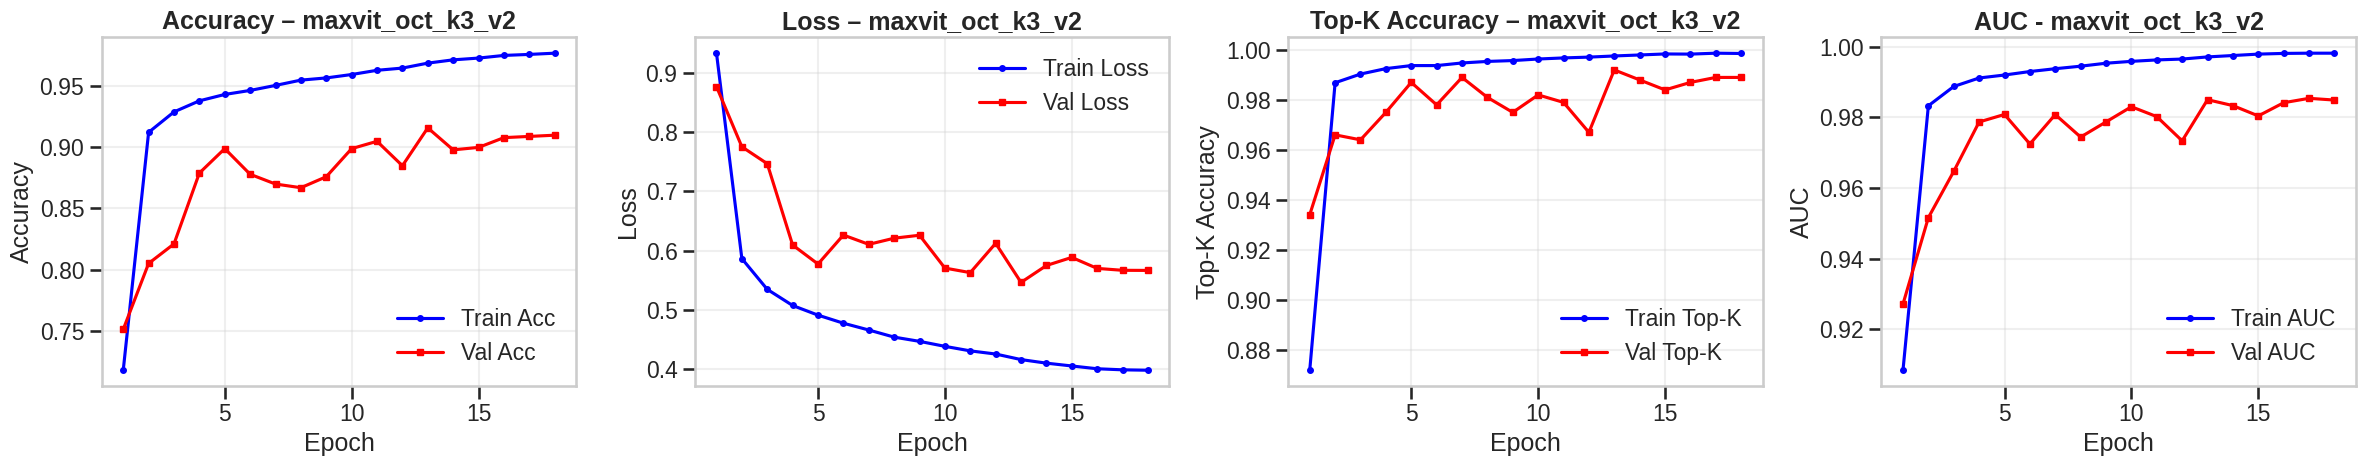

  Đã lưu: /kaggle/working/maxvit_oct_outputs/plots/maxvit_oct_k3_v2_training_curves.png


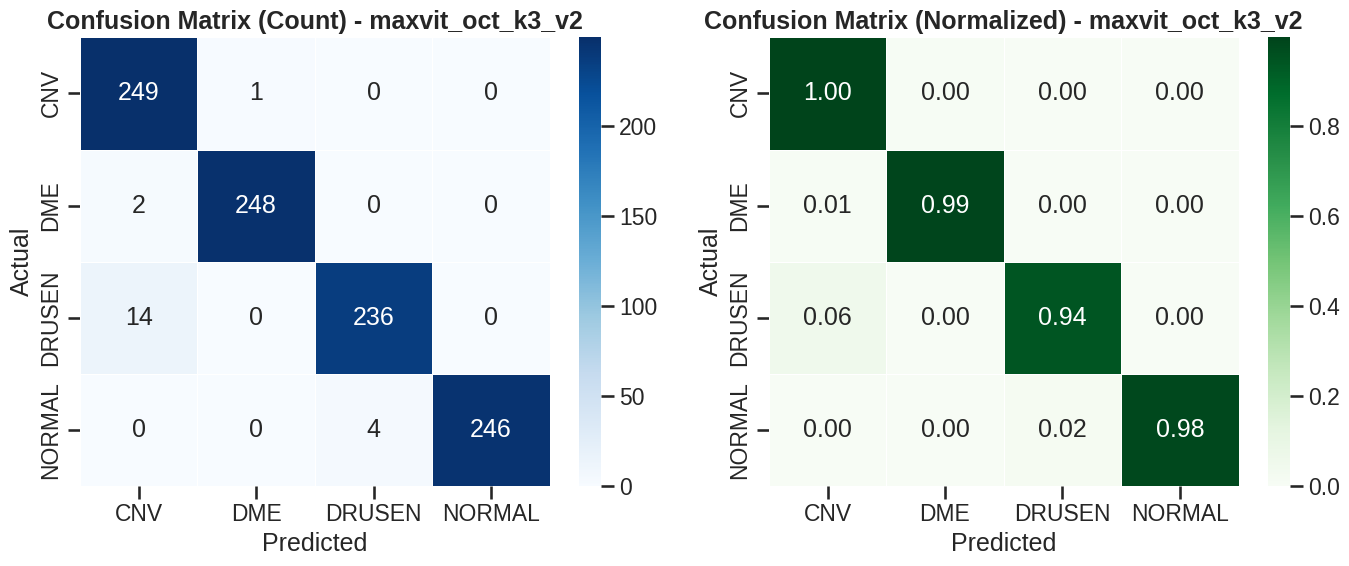

  Đã lưu: /kaggle/working/maxvit_oct_outputs/plots/maxvit_oct_k3_v2_confusion_matrix.png


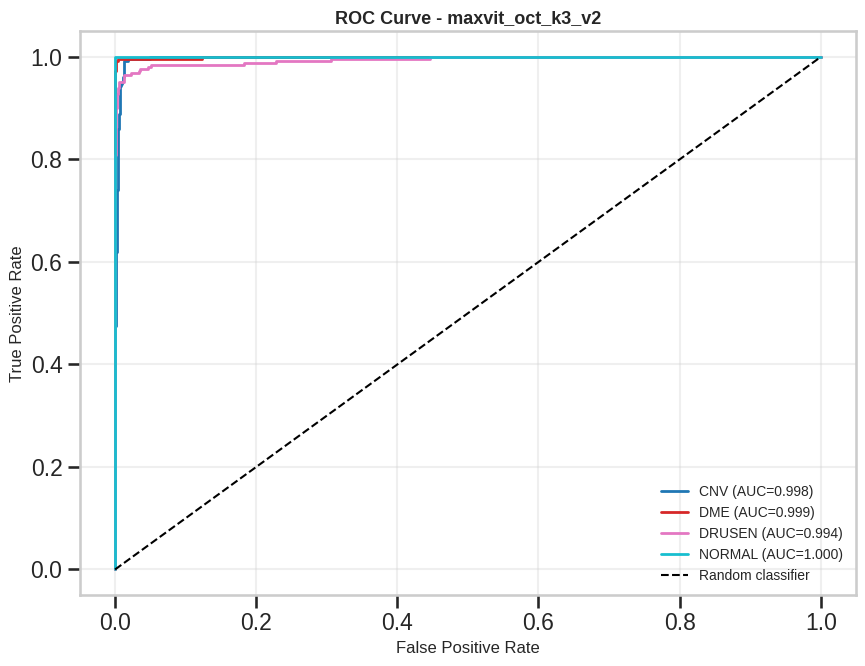

  Đã lưu: /kaggle/working/maxvit_oct_outputs/plots/maxvit_oct_k3_v2_roc_curve.png
Đã lưu tất cả biểu đồ vào: /kaggle/working/maxvit_oct_outputs/plots


In [12]:
# ======================================================
# VẼ TẤT CẢ BIỂU ĐỒ ĐÁNH GIÁ SAU KHI HUẤN LUYỆN
# ======================================================
print('Đang vẽ biểu đồ kết quả MaxViT...')

# Đường cong loss / accuracy / top-k accuracy theo epoch
plot_training_history(hist_maxvit, RUN_NAME)

# Confusion matrix (số mẫu + chuẩn hóa)
plot_confusion_matrix(yt, yp, RUN_NAME, CLASS_NAMES)

# Đường cong ROC per-class
plot_roc_curve(yt, yprob, RUN_NAME, CLASS_NAMES)

print('Đã lưu tất cả biểu đồ vào:', PLOTS_DIR)


## 12. Tóm tắt kết quả & Đóng gói output


In [13]:
# ======================================================
# BẢNG KẾT QUẢ TỔNG HỢP VÀ LƯU CSV
# ======================================================
import pandas as pd

# Tạo DataFrame từ dict kết quả, chọn đúng thứ tự cột
df_res = pd.DataFrame([res_maxvit])[[
    'run_name', 'epochs_ran',
    'test_loss', 'test_acc', 'test_topk',
    'roc_auc', 'precision_macro', 'recall_macro',
    'specificity', 'f1_macro', 'train_time_m',
]]
df_res.columns = [
    'Tên Run', 'Epoch thực tế',
    'Test Loss', 'Test Accuracy', 'Test Top-K',
    'Test AUC-ROC', 'Test Precision', 'Test Recall/Sens',
    'Test Specificity', 'Test F1-score', 'Thời gian (phút)',
]

# Format các cột dạng phần trăm và thập phân
df_res['Test Accuracy'] = df_res['Test Accuracy'].apply(lambda x: f'{x * 100:.2f}%')
df_res['Test Top-K']    = df_res['Test Top-K'].apply(   lambda x: f'{x * 100:.2f}%')
for col in ['Test Loss', 'Test AUC-ROC', 'Test Precision',
            'Test Recall/Sens', 'Test Specificity', 'Test F1-score']:
    df_res[col] = df_res[col].apply(lambda x: f'{x:.4f}')

print('=' * 90)
print('BẢNG KẾT QUẢ – MaxViT OCT (Keras 3)')
print('=' * 90)
for col in df_res.columns:
    print(f'  {col:<22}: {df_res[col].values[0]}')
print('=' * 90)

# Lưu summary CSV
summary_csv = LOGS_DIR / f'{RUN_NAME}_summary.csv'
df_res.to_csv(str(summary_csv), index=False, encoding='utf-8-sig')
print(f'\n  Đã lưu: {summary_csv}')
print(f'  Đã lưu: {LOGS_DIR / f"{RUN_NAME}_per_class_metrics.csv"}')
print(f'  Đã lưu: {REPORTS_DIR / f"{RUN_NAME}_classification_report.txt"}')


BẢNG KẾT QUẢ – MaxViT OCT (Keras 3)
  Tên Run               : maxvit_oct_k3_v2
  Epoch thực tế         : 18
  Test Loss             : 0.1441
  Test Accuracy         : 97.90%
  Test Top-K            : 99.80%
  Test AUC-ROC          : 0.9978
  Test Precision        : 0.9797
  Test Recall/Sens      : 0.9790
  Test Specificity      : 0.9930
  Test F1-score         : 0.9790
  Thời gian (phút)      : 467.57

  Đã lưu: /kaggle/working/maxvit_oct_outputs/logs/maxvit_oct_k3_v2_summary.csv
  Đã lưu: /kaggle/working/maxvit_oct_outputs/logs/maxvit_oct_k3_v2_per_class_metrics.csv
  Đã lưu: /kaggle/working/maxvit_oct_outputs/reports/maxvit_oct_k3_v2_classification_report.txt


In [14]:
# ======================================================
# KIỂM TRA CÁC FILE ĐÃ XUẤT
# ======================================================
print('=' * 50)
print('CÁC FILE TRONG /kaggle/working')
print('=' * 50)
for root, dirs, files in os.walk('/kaggle/working'):
    level     = root.replace('/kaggle/working', '').count(os.sep)
    indent    = '  ' * level
    folder    = os.path.basename(root)
    # Bỏ qua liệt kê sâu vào thư mục ảnh đã tiền xử lý
    if 'preprocessed_oct' in root and level > 2:
        continue
    if folder != 'working':
        print(f'{indent}{folder}/')
    subindent = '  ' * (level + 1)
    for f in files:
        fpath = os.path.join(root, f)
        size  = os.path.getsize(fpath)
        # Hiển thị kích thước theo đơn vị phù hợp
        szstr = (f'{size / 1e6:.1f} MB' if size > 1e6
                 else f'{size / 1e3:.1f} KB' if size > 1e3
                 else f'{size} B')
        print(f'{subindent}{f} ({szstr})')


CÁC FILE TRONG /kaggle/working
  __notebook__.ipynb (9.1 MB)
  maxvit_oct_outputs/
    reports/
      maxvit_oct_k3_v2_summary.json (404 B)
      maxvit_oct_k3_v2_classification_report.txt (434 B)
    models/
      maxvit_oct_k3_v2_final.keras (204.3 MB)
      maxvit_oct_k3_v2_best.keras (204.3 MB)
    plots/
      maxvit_oct_k3_v2_confusion_matrix.png (124.7 KB)
      class_distribution.png (83.9 KB)
      maxvit_oct_k3_v2_training_curves.png (210.7 KB)
      maxvit_oct_k3_v2_roc_curve.png (84.7 KB)
    logs/
      maxvit_oct_k3_v2_summary.csv (244 B)
      maxvit_oct_k3_v2_per_class_metrics.csv (319 B)
      maxvit_oct_k3_v2_history.csv (2.9 KB)


In [15]:
# ======================================================
# ĐÓNG GÓI TOÀN BỘ OUTPUT THÀNH FILE ZIP
# ======================================================
import subprocess

# Đóng gói OUTPUT_DIR thành zip, loại trừ chính file zip để tránh vòng lặp
zip_result = subprocess.run(
    ['zip', '-r', str(ZIP_PATH), '.', '--exclude', './outputs.zip'],
    capture_output=True, text=True, cwd=str(OUTPUT_DIR)
)
if os.path.exists(str(ZIP_PATH)):
    size_mb = os.path.getsize(str(ZIP_PATH)) / 1e6
    print(f'  outputs.zip sẵn sàng ({size_mb:.1f} MB)')
    print('  Tải về từ Kaggle Notebook → Output → outputs.zip')
else:
    print('  Lỗi: Không tìm thấy outputs.zip')
    if zip_result.stderr:
        print('  stderr:', zip_result.stderr[:300])

print('\n  NOTEBOOK HOÀN TẤT!')
print('=' * 70)


  outputs.zip sẵn sàng (367.6 MB)
  Tải về từ Kaggle Notebook → Output → outputs.zip

  NOTEBOOK HOÀN TẤT!
